In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

In [6]:
df = pd.read_csv("water.csv")

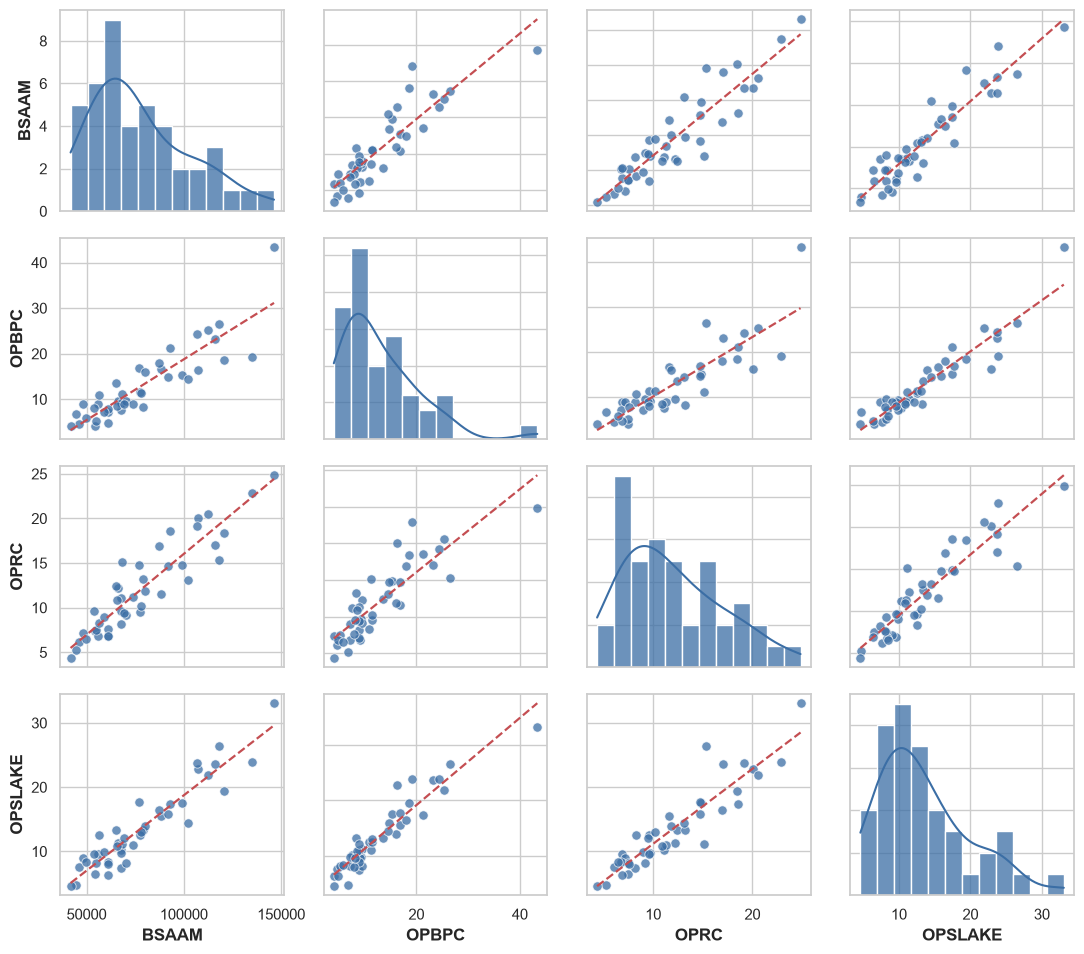

In [8]:
# 8.1 (3.6.1) 散点图矩阵：BSAAM 与 OPBPC, OPRC, OPSLAKE
sns.set_theme(style="whitegrid", context="notebook")

vars_ = ["BSAAM", "OPBPC", "OPRC", "OPSLAKE"]
data = df[vars_]

n = len(vars_)
fig, axes = plt.subplots(n, n, figsize=(11, 10))
fig.patch.set_facecolor("white")
color = "#3b6ea5"

for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        if i == j:  # 对角线：直方图 + 核密度曲线
            sns.histplot(data[vars_[i]], bins=12, kde=True, color=color,
                         edgecolor="white", alpha=.75, ax=ax)
        else:       # 非对角线：散点 + 最小二乘拟合线
            x, y = data[vars_[j]], data[vars_[i]]
            ax.scatter(x, y, s=45, color=color, alpha=.75,
                       edgecolor="white", linewidth=.6, zorder=3)
            slope, intercept = np.polyfit(x, y, 1)
            xs = np.linspace(x.min(), x.max(), 100)
            ax.plot(xs, intercept + slope * xs,
                    color="#c44e52", lw=1.6, ls="--", zorder=4)
        ax.tick_params(labelbottom=(i == n - 1), labelleft=(j == 0))
        if i < n - 1: ax.set_xlabel("")
        if j > 0:     ax.set_ylabel("")

for k, v in enumerate(vars_):
    axes[n - 1, k].set_xlabel(v, fontsize=12, fontweight="bold")
    axes[k, 0].set_ylabel(v, fontsize=12, fontweight="bold")

fig.tight_layout(rect=(0, 0, 1, .97))

fig.savefig("assets/scatter-matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
model = smf.ols(
    "BSAAM ~ OPBPC + OPRC + OPSLAKE",
    data=df
).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  BSAAM   R-squared:                       0.902
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                     119.2
Date:                Tue, 22 Sep 2026   Prob (F-statistic):           1.10e-19
Time:                        21:26:23   Log-Likelihood:                -446.97
No. Observations:                  43   AIC:                             901.9
Df Residuals:                      39   BIC:                             909.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   2.299e+04   3545.315      6.485      0.000    1.58e+04    3.02e+04
OPBPC         40.6095    502.399      0.081      0.936    -975.589    1056.807
OPRC        1867.4559    647.039      2.886      0.006     558.696    3176.216
OPSLAKE     2353.9564    771.706      3.050      0.004     793.033    3914.880
==============================================================================
Omnibus:                        0.732   Durbin-Watson:                   1.659
Prob(Omnibus):                  0.694   Jarque-Bera (JB):                0.697
Skew:                           0.286   Prob(JB):                        0.706
Kurtosis:                       2.753   Cond. No.                         69.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [10]:
boston = pd.read_csv("Boston.csv")
print("数据维度:", boston.shape)
boston.head()

数据维度: (506, 14)


,CRIM,ZN,INDUS,CHAS,NX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [11]:
# 9.1 多元线性回归：MEDV ~ 所有其他特征
features = [c for c in boston.columns if c != "MEDV"]
formula_full = "MEDV ~ " + " + ".join(features)
model_full = smf.ols(formula=formula_full, data=boston).fit()
model_full.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MEDV   R-squared:                       0.741
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     108.1
Date:                Tue, 22 Sep 2026   Prob (F-statistic):          6.72e-135
Time:                        21:26:23   Log-Likelihood:                -1498.8
No. Observations:                 506   AIC:                             3026.
Df Residuals:                     492   BIC:                             3085.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     36.4595      5.103      7.144      0.000      26.432      46.487
CRIM          -0.1080      0.033     -3.287      0.001      -0.173      -0.043
ZN             0.0464      0.014      3.382      0.001       0.019       0.073
INDUS          0.0206      0.061      0.334      0.738      -0.100       0.141
CHAS           2.6867      0.862      3.118      0.002       0.994       4.380
NX           -17.7666      3.820     -4.651      0.000     -25.272     -10.262
RM             3.8099      0.418      9.116      0.000       2.989       4.631
AGE            0.0007      0.013      0.052      0.958      -0.025       0.027
DIS           -1.4756      0.199     -7.398      0.000      -1.867      -1.084
RAD            0.3060      0.066      4.613      0.000       0.176       0.436
TAX           -0.0123      0.004     -3.280      0.001      -0.020      -0.005
PTRATIO       -0.9527      0.131     -7.283      0.000      -1.210      -0.696
B              0.0093      0.003      3.467      0.001       0.004       0.015
LSTAT         -0.5248      0.051    -10.347      0.000      -0.624      -0.425
==============================================================================
Omnibus:                      178.041   Durbin-Watson:                   1.078
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              783.126
Skew:                           1.521   Prob(JB):                    8.84e-171
Kurtosis:                       8.281   Cond. No.                     1.51e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.51e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

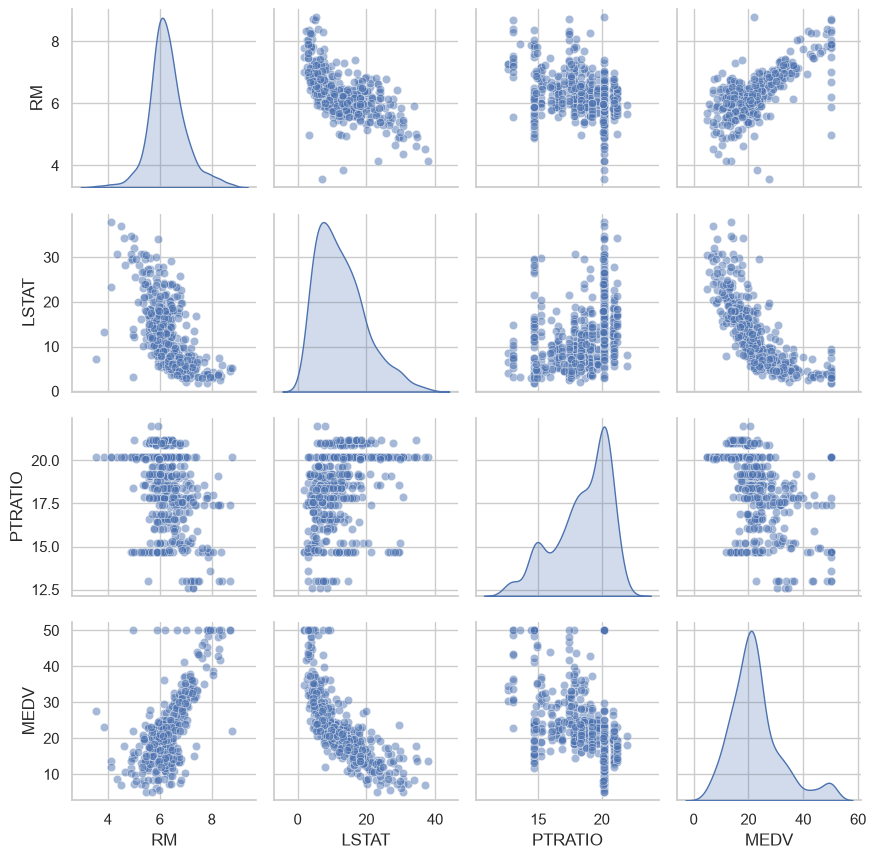

In [12]:
# 9.2 散点图矩阵：选取 RM, LSTAT, PTRATIO 三个自变量及因变量 MEDV
selected_vars = ["RM", "LSTAT", "PTRATIO", "MEDV"]
sns.set_theme(style="whitegrid", context="notebook")
g = sns.pairplot(
    boston[selected_vars],
    diag_kind="kde",
    plot_kws={"alpha": 0.5},
    height=2.2
)
# g.fig.suptitle("Scatterplot Matrix: RM, LSTAT, PTRATIO vs MEDV", y=1.02)
plt.tight_layout()
plt.savefig("assets/boston-scatter-matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# 9.3 多重共线性诊断：VIF
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = boston[features]
X_const = sm.add_constant(X)

vif_df = pd.DataFrame()
vif_df["Variable"] = features
vif_df["VIF"] = [
    variance_inflation_factor(X_const.values, i + 1)
    for i in range(len(features))
]
vif_df = vif_df.sort_values("VIF", ascending=False)
vif_df

,Variable,VIF
9,TAX,9.008554
8,RAD,7.484496
4,NX,4.393720
2,INDUS,3.991596
7,DIS,3.955945
6,AGE,3.100826
12,LSTAT,2.941491
1,ZN,2.298758
5,RM,1.933744
10,PTRATIO,1.799084


In [14]:
# 9.3 多重共线性诊断：kappa（条件数）
sv = np.linalg.svd(X, compute_uv=False)
print("最大奇异值 sigma_max = {:.4f}".format(sv.max()))
print("最小奇异值 sigma_min = {:.6f}".format(sv.min()))
kappa = sv.max() / sv.min()
print("条件数 kappa = {:.2f}".format(kappa))

最大奇异值 sigma_max = 12585.1816
最小奇异值 sigma_min = 1.480969
条件数 kappa = 8497.94


In [15]:
# 去掉 RAD 后再拟合，比较回归效果
reduced_features = [c for c in features if c != "RAD"]
formula_reduced = "MEDV ~ " + " + ".join(reduced_features)
model_reduced = smf.ols(formula=formula_reduced, data=boston).fit()

comparison = pd.DataFrame({
    "Metric": ["R-squared", "Adj. R-squared", "AIC", "BIC", "F-statistic"],
    "Full Model": [
        model_full.rsquared,
        model_full.rsquared_adj,
        model_full.aic,
        model_full.bic,
        model_full.fvalue,
    ],
    "Reduced (no RAD)": [
        model_reduced.rsquared,
        model_reduced.rsquared_adj,
        model_reduced.aic,
        model_reduced.bic,
        model_reduced.fvalue,
    ],
})
comparison.round(4)

,Metric,Full Model,Reduced (no RAD)
0,R-squared,0.7406,0.7294
1,Adj. R-squared,0.7338,0.7228
2,AIC,3025.6086,3045.0329
3,BIC,3084.7801,3099.9779
4,F-statistic,108.0767,110.7541


In [18]:
# 简化模型的 VIF
X_r = boston[reduced_features]
X_r_const = sm.add_constant(X_r)
vif_r = pd.DataFrame()
vif_r["Variable"] = reduced_features
vif_r["VIF"] = [
    variance_inflation_factor(X_r_const.values, i + 1)
    for i in range(len(reduced_features))
]
print(vif_r.sort_values("VIF", ascending=False))

   Variable       VIF
4        NX  4.304929
7       DIS  3.954951
2     INDUS  3.682265
8       TAX  3.415289
6       AGE  3.083009
11    LSTAT  2.937752
1        ZN  2.273018
5        RM  1.885425
9   PTRATIO  1.734873
0      CRIM  1.664471
10        B  1.341459
3      CHAS  1.061561
